In [1]:
!pip install torch==2.1.2 torchvision==0.16.2 torchaudio==2.1.2 --index-url https://download.pytorch.org/whl/cpu
!pip install transformers librosa mamkit

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached https://download.pytorch.org/whl/cpu/torch-2.1.2%2Bcpu-cp311-cp311-linux_x86_64.whl (184.9 MB)
  Using cached https://download.pytorch.org/whl/cpu/torchaudio-2.1.2%2Bcpu-cp311-cp311-linux_x86_64.whl (1.6 MB)
  Attempting uninstall: torch
    Found existing installation: torch 2.3.0
    Uninstalling torch-2.3.0:
      Successfully uninstalled torch-2.3.0
  Attempting uninstall: torchaudio
    Found existing installation: torchaudio 2.3.0
    Uninstalling torchaudio-2.3.0:
      Successfully uninstalled torchaudio-2.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mamkit 0.1.1 requires torch==2.3.0, but you have torch 2.1.2+cpu which is incompatible.
mamkit 0.1.1 requires torchaudio==2.3.0, but you have torchaudio 2.1.2+cpu which is incompatible.
torchtext 0.18.0 requires torch>=2.3.0, but

In [3]:
# --- Setup ---
from pathlib import Path
import torch
import torch.nn as nn
from transformers import RobertaTokenizer, RobertaModel
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from mamkit.data.datasets import MMUSEDFallacy, InputMode

/usr/local/lib/python3.11/dist-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: '/usr/local/lib/python3.11/dist-packages/torchvision/image.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


In [4]:
from google.colab import drive
drive.mount('/content/drive')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Task A: Fallacy Detection (Binary Classification)

In [5]:
#  Load Dataset
base_data_path = Path("/content/data")
test_dataset = MMUSEDFallacy(task_name='afd', input_mode=InputMode.TEXT_ONLY, base_data_path=base_data_path)

Downloading: https://zenodo.org/api/records/14938117/files-archive: 5.71MB [00:10, 585kB/s]
  0%|          | 0/35 [00:00<?, ?it/s]

[youtube] Extracting URL: https://www.youtube.com/watch?v=_hEeMvhcNlE&t=4579s
[youtube] _hEeMvhcNlE: Downloading webpage
[youtube] _hEeMvhcNlE: Downloading tv client config
[youtube] _hEeMvhcNlE: Downloading player d71837c8
[youtube] _hEeMvhcNlE: Downloading tv player API JSON
[youtube] _hEeMvhcNlE: Downloading ios player API JSON


         player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         n = HB4D3gL2HbZ8Qqsj ; player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         n = zHv8F9ODw-YED6wg ; player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         n = 4uEGzwBvUnMKrdpo ; player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js


[youtube] _hEeMvhcNlE: Downloading m3u8 information
[info] _hEeMvhcNlE: Downloading 1 format(s): 234
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 1094
[download] Destination: /content/data/MMUSED-fallacy/audio_recordings/30_2004/full_audio
[download] 100% of   90.82MiB in 00:00:53 at 1.68MiB/s                     
[ExtractAudio] Destination: /content/data/MMUSED-fallacy/audio_recordings/30_2004/full_audio.wav
Deleting original file /content/data/MMUSED-fallacy/audio_recordings/30_2004/full_audio (pass -k to keep)


  3%|▎         | 1/35 [01:10<39:53, 70.39s/it]

[youtube] Extracting URL: https://www.youtube.com/watch?v=xdQK78l3Xhc&t=119s
[youtube] xdQK78l3Xhc: Downloading webpage
[youtube] xdQK78l3Xhc: Downloading tv client config
[youtube] xdQK78l3Xhc: Downloading player d71837c8
[youtube] xdQK78l3Xhc: Downloading tv player API JSON
[youtube] xdQK78l3Xhc: Downloading ios player API JSON


... (131 outputs left out)

[youtube] Extracting URL: https://www.youtube.com/watch?v=UCA1A5GqCdQ&ab_channel=NBCNews
[youtube] UCA1A5GqCdQ: Downloading webpage
[youtube] UCA1A5GqCdQ: Downloading tv client config
[youtube] UCA1A5GqCdQ: Downloading player d71837c8
[youtube] UCA1A5GqCdQ: Downloading tv player API JSON
[youtube] UCA1A5GqCdQ: Downloading ios player API JSON


         player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         n = irkl8ZtGaTmoY8o4 ; player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         n = 0UZR5k8cCiaE-Wur ; player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js
         n = UB0Bdopis1Rbm1nC ; player = https://www.youtube.com/s/player/d71837c8/player_ias.vflset/en_US/base.js


[youtube] UCA1A5GqCdQ: Downloading m3u8 information
[info] UCA1A5GqCdQ: Downloading 1 format(s): 234
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 1345
[download] Destination: /content/data/MMUSED-fallacy/audio_recordings/46_2020/full_audio
[download] 100% of  111.60MiB in 00:01:13 at 1.52MiB/s                     
[ExtractAudio] Destination: /content/data/MMUSED-fallacy/audio_recordings/46_2020/full_audio.wav
Deleting original file /content/data/MMUSED-fallacy/audio_recordings/46_2020/full_audio (pass -k to keep)


Building clips...: 100%|██████████| 35/35 [05:57<00:00, 10.22s/it]


In [6]:
# Wrap Dataset for Testing
class WrappedAFD(Dataset):
    def __init__(self, mmused_dataset):
        self.df = mmused_dataset.data

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        return {
            'text': row['sentence'],
            'label': row['label']
        }

    def __len__(self):
        return len(self.df)

wrapped_dataset = WrappedAFD(test_dataset)

Building AFD data...: 100%|██████████| 35/35 [00:01<00:00, 17.61it/s]


In [7]:
# Tokenizer & DataLoader
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

In [8]:
def collate_fn(batch):
    texts = [item['text'] for item in batch]
    labels = torch.tensor([item['label'] for item in batch])
    encodings = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=128)
    return encodings, labels

dataloader = DataLoader(wrapped_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)

In [9]:
#  Define Model
class RobertaBinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained('roberta-base')
        self.classifier = nn.Linear(self.roberta.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(outputs.last_hidden_state[:, 0])

In [11]:
#  Load Trained Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RobertaBinaryClassifier().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/task_a_model.pt"))
model.eval()

#  Run Evaluation
all_preds, all_labels = [], []
with torch.no_grad():
    for batch in dataloader:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        logits = model(**inputs)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Print Report
print("Classification Report (Task A):")
print(classification_report(all_labels, all_preds))

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Classification Report (Task A):
              precision    recall  f1-score   support

           0       0.92      0.99      0.95     15550
           1       0.58      0.15      0.24      1568

    accuracy                           0.91     17118
   macro avg       0.75      0.57      0.60     17118
weighted avg       0.89      0.91      0.89     17118



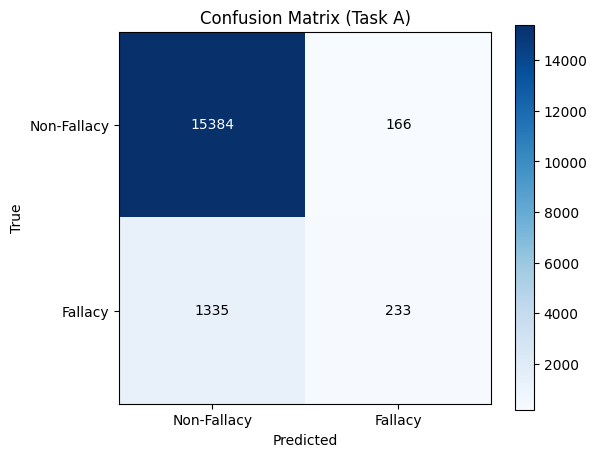

In [12]:
# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix (Task A)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks([0, 1], ["Non-Fallacy", "Fallacy"])
plt.yticks([0, 1], ["Non-Fallacy", "Fallacy"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.colorbar()


# Task B: Fallacy Classification (6 Classes)

In [13]:
# Load Dataset
full_dataset = MMUSEDFallacy(task_name='afc', input_mode=InputMode.TEXT_ONLY, base_data_path=base_data_path)


In [14]:
# Wrap Dataset
class WrappedAFC(Dataset):
    def __init__(self, mmused_dataset, tokenizer, max_length):
        self.df = mmused_dataset.data
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = row['snippet']
        label = row['fallacy']
        inputs = self.tokenizer(text, padding='max_length', truncation=True,
                                max_length=self.max_length, return_tensors="pt")
        item = {key: val.squeeze(0) for key, val in inputs.items()}
        item['label'] = torch.tensor(label)
        return item

    def __len__(self):
        return len(self.df)

wrapped_dataset = WrappedAFC(full_dataset, tokenizer, max_length=128)


Building AFC Context: 100%|██████████| 1278/1278 [00:00<00:00, 9836.46it/s] 


In [15]:
def collate_fn(batch):
    input_keys = batch[0].keys()
    inputs = {k: torch.stack([d[k] for d in batch]) for k in input_keys if k != 'label'}
    labels = torch.tensor([d['label'] for d in batch])
    return inputs, labels

dataloader = DataLoader(wrapped_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)


In [16]:
#  Define Classifier
class RobertaFallacyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained('roberta-base')
        self.classifier = nn.Linear(self.roberta.config.hidden_size, 6)

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(outputs.last_hidden_state[:, 0])


In [17]:
# Load Trained Model
model = RobertaFallacyClassifier().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/task_b_model.pt"))
model.eval()

# Evaluation
all_preds, all_labels = [], []
with torch.no_grad():
    for batch in dataloader:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        logits = model(**inputs)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Classification Report (Task B):")
print(classification_report(all_labels, all_preds))

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Classification Report (Task B):
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       800
           1       0.95      0.86      0.90       191
           2       0.89      0.89      0.89       149
           3       0.86      0.75      0.80        56
           4       0.72      0.93      0.81        46
           5       0.91      0.81      0.85        36

    accuracy                           0.92      1278
   macro avg       0.88      0.87      0.87      1278
weighted avg       0.93      0.92      0.92      1278



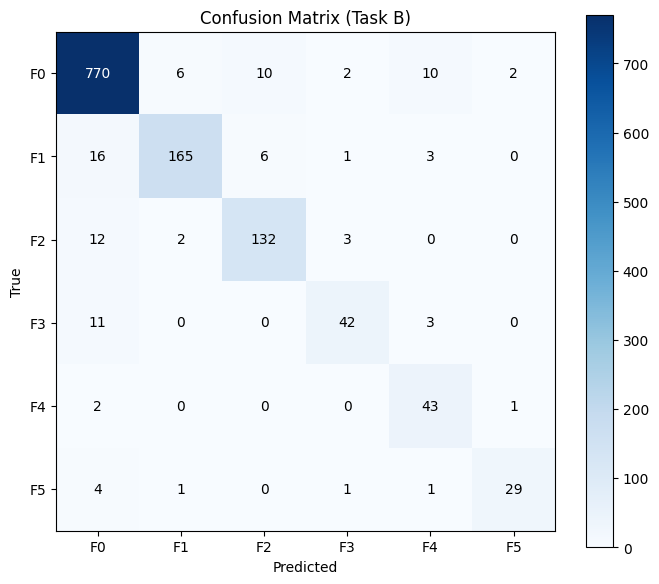

In [18]:
# Confusion Matrix \
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7,6))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix (Task B)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(6), [f"F{i}" for i in range(6)])
plt.yticks(range(6), [f"F{i}" for i in range(6)])
for i in range(6):
    for j in range(6):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.colorbar()
plt.tight_layout()
plt.show()